In [1]:
import pandas as pd  # 导入pandas库，用于数据处理和分析，特别是DataFrame操作
import numpy as np  # 导入numpy库，用于进行数值计算，特别是数组操作
import matplotlib.pyplot as plt  # 导入matplotlib的pyplot模块，用于绘制图表
import matplotlib  # 导入matplotlib主库，用于更底层的绘图设置
from matplotlib import font_manager
from tools import (
    plot_regression_fit3,
    plot_importance_combined,
    plot_residuals_styled,
    manual_pdp_1d,
    manual_pdp_2d,
    plot_3d_scatter_three_features,
    plot_3d_pdp_fixed_value,
    data_norm_get,
    create_and_save_summary_plot,
    create_and_save_top_dependence_plots,
    create_and_save_interaction_heatmap,
    create_and_save_top_interaction_dependence_plots,
)
from pygam import LinearGAM, s

f:\py\Multi_algorithm_comparison_basic_version\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
def plot_result(x,y,out):
    nature_colors = {
        "blue": "#1f77b4",
        "orange": "#ff7f0e",
        "green": "#2ca02c",
        "red": "#d62728",
        "purple": "#9467bd",
        "gray": "#7f7f7f",
    }
    x_vals = x.values.reshape(-1, 1)
    y_vals = y.values.reshape(-1, 1)
    x_name = x.name
    y_name = y.name
    fig_dep, ax_dep = plt.subplots(figsize=(7, 5))
    gam = LinearGAM(s(0), n_splines=10).fit(x_vals, y_vals)
    x_pred = np.linspace(x_vals.min(), x_vals.max(), 300)
    y_pred = gam.predict(x_pred)
    XX = gam.generate_X_grid(term=0, n=300)
    predictions = gam.prediction_intervals(XX, width=0.95)
    ax_dep.scatter(
            x_vals, y_vals, color=nature_colors["blue"], alpha=0.3, zorder=1, s=10
        )
    ax_dep.plot(
            x_pred,
            y_pred,
            color=nature_colors["blue"],
            linewidth=2,
            zorder=3,
        )
    ax_dep.fill_between(
            XX.flatten(),
            predictions[:, 0],
            predictions[:, 1],
            color=nature_colors["gray"],
            alpha=0.3,
            zorder=0,
        )
    ax_dep.set_ylabel(y_name, fontsize=16)
    ax_dep.set_xlabel(x_name, fontsize=16)
    ax_dep.legend(fontsize=16)
    ax_dep.minorticks_on()
    ax_dep.grid(True, which="both")
    filename = f"{out}.png"
    fig_dep.savefig(filename, dpi=300, bbox_inches="tight")


In [5]:
df = pd.read_csv("E:/baidubackup/BaiduSyncdisk/博士毕业论文/图/3/YOLOv8n-C2f-DCNV3-groupnorm.csv")
df


,epoch,train/box_loss,train/cls_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss
0,1,2.07530,1.87270,0.61204,0.66961,0.59207,0.31795,1.49970,1.76320
1,2,1.55230,1.28370,0.94003,0.81887,0.87135,0.54662,1.23250,1.06400
2,3,1.24230,1.04690,0.94943,0.85658,0.90208,0.68709,0.90137,0.79251
3,4,1.02770,0.87442,0.95431,0.86061,0.91330,0.75316,0.74046,0.68256
4,5,0.88455,0.75482,0.97025,0.86461,0.92158,0.77988,0.63940,0.58108
...,...,...,...,...,...,...,...,...,...
395,396,0.21176,0.17237,0.99401,0.97057,0.98709,0.97064,0.14233,0.11969
396,397,0.21272,0.16994,0.99547,0.96968,0.98707,0.97064,0.14238,0.11963
397,398,0.21136,0.17191,0.99353,0.97057,0.98700,0.97007,0.14249,0.11980
398,399,0.21127,0.17020,0.99294,0.97204,0.98702,0.97005,0.14261,0.11980


In [6]:
x=df["epoch"]
y=df["train/cls_loss"]


In [11]:
plot_result(x, y,out="train_cls")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


In [2]:
df=pd.read_excel('E:/baidubackup/BaiduSyncdisk/博士毕业论文/图/3/固定相机.xlsx')
df=df[:150].sample(frac=1).reset_index(drop=True)
df

,Unnamed: 0,disp,res,Unnamed: 3,Unnamed: 4
0,19,0.053120,-53.180020,-0.060404,0.060404
1,169,-0.035862,35.899017,0.036840,0.036840
2,106,0.018681,-18.702997,-0.022196,0.022196
3,1,0.000000,0.000000,0.000000,0.000000
4,129,-0.054969,55.028552,0.059398,0.059398
...,...,...,...,...,...
145,79,-0.057430,57.491527,0.061756,0.061756
146,178,0.029504,-29.536000,-0.031830,0.031830
147,92,0.066949,-67.027349,-0.077891,0.077891
148,42,-0.049002,49.053246,0.051449,0.051449


In [9]:
df["res"].max()

69.6630948745664

In [3]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
df["disp"] = -df["disp"]*1000
test_mse = mean_squared_error(df["res"],df["disp"])  # 计算测试集的均方误差(MSE)
test_rmse = np.sqrt(test_mse)  # 计算测试集的均方根误差(RMSE)
test_mae = mean_absolute_error(df["res"],df["disp"])  # 计算测试集的平均绝对误差(MAE)
test_r2 = r2_score(df["res"],df["disp"])  # 计算测试集的R2值

In [4]:
plot_regression_fit3(df["res"],df["disp"],test_r2,test_rmse,test_mae,"算法预测值","预测值与理论值对比","disp.png")

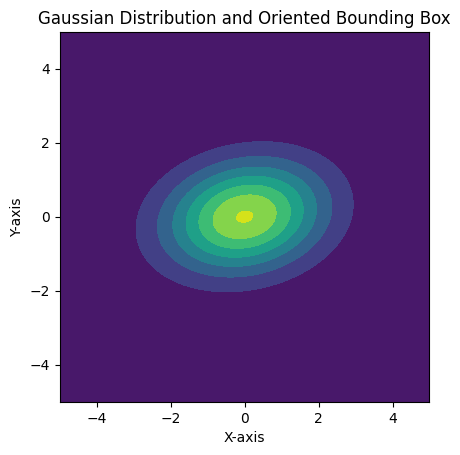

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

# 定义旋转框的参数
center = np.array([0, 0])  # 中心点
size = np.array([1, 1.5])    # 尺寸 (长宽)
angle = -np.pi / 2.3          # 旋转角度 (弧度)

# 计算协方差矩阵
rotation_matrix = np.array([
    [np.cos(angle), -np.sin(angle)],
    [np.sin(angle), np.cos(angle)]
])
covariance_matrix = np.diag(size ** 2)  # 方差矩阵
rotated_covariance_matrix = rotation_matrix @ covariance_matrix @ rotation_matrix.T

# 创建网格用于绘制高斯分布
x, y = np.mgrid[-5:5:.01, -5:5:.01]
pos = np.dstack((x, y))
rv = multivariate_normal(center, rotated_covariance_matrix)

# 绘制高斯分布
fig, ax = plt.subplots()
ax.contourf(x, y, rv.pdf(pos), cmap='viridis')


# 设置图形属性
ax.set_aspect('equal', 'box')
plt.title('Gaussian Distribution and Oriented Bounding Box')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.savefig('gaussian_distribution.tif')
plt.show()